In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [3]:
df = pd.read_csv('https://docs.google.com/spreadsheets/d/e/2PACX-1vRuzXARgJRfsAFFuWGc5PDv5pcJbvn6drznZde0VnJQPD_TqRuuTDOAJIHtI0XY6KynfaYfkeau2GFi/pub?gid=1638308872&single=true&output=csv')

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [8]:
df.describe(include='object').T

,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,B96 B98,4
Embarked,889,3,S,644


In [9]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [10]:
df.shape

(891, 12)

In [11]:
print(df.duplicated().sum())

0


In [12]:
df.drop_duplicates()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [13]:
df.shape

(891, 12)

In [14]:
print(df['Survived'].value_counts())

Survived
0    549
1    342
Name: count, dtype: int64


In [15]:
# plt.figure(figsize=(10,6))
# sns.countplot(data=df, x='Survived')
# plt.title('Distribution of Survived')
# plt.xlabel('Survived')
# plt.ylabel('Count')
# plt.show()

In [16]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [17]:
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})


df['Cabin'] = df['Cabin'].apply(lambda x: 0 if pd.isnull(x) else 1)

df['Embarked'] = df['Embarked'].map({'C': 0, 'Q': 1, 'S': 2})

df['Age'].fillna(df['Age'].median(), inplace=True)

df = df.dropna(subset=['Embarked'])

In [18]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

In [19]:
X = df.drop(columns=['Survived', 'Name', 'Ticket'])
y=df['Survived']


In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [21]:
models = {
    'Random Forest': RandomForestClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'Support Vector Machine': SVC(),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Logistic Regression': LogisticRegression()
}

In [22]:
models = {
    'Random Forest': RandomForestClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'Support Vector Machine': SVC(),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Logistic Regression': LogisticRegression()
}

for model_name, model in models.items():
    print(f"Training {model_name}...")
    # CHANGED: 'models.fit' to 'model.fit'
    model.fit(X_train, y_train) 

Training Random Forest...
Training Decision Tree...
Training Support Vector Machine...
Training K-Nearest Neighbors...
Training Logistic Regression...


c:\Users\ipcs nagpur\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Assuming your models dictionary is already trained...

print(f"{'Model':<25} | {'Accuracy':<10} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10}")
print("-" * 75)

for model_name, model in models.items():
    # 1. Generate predictions using the test set
    y_pred = model.predict(X_test)
    
    # 2. Calculate individual metrics
    # Note: For multi-class classification, change average='binary' to average='macro' or 'weighted'
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='binary')
    recall = recall_score(y_test, y_pred, average='binary')
    f1 = f1_score(y_test, y_pred, average='binary')
    
    # 3. Print metrics formatted cleanly in a table
    print(f"{model_name:<25} | {accuracy:<10.4f} | {precision:<10.4f} | {recall:<10.4f} | {f1:<10.4f}")


Model                     | Accuracy   | Precision  | Recall     | F1-Score  
---------------------------------------------------------------------------
Random Forest             | 0.7921     | 0.7286     | 0.7391     | 0.7338    
Decision Tree             | 0.7191     | 0.6234     | 0.6957     | 0.6575    
Support Vector Machine    | 0.6348     | 0.7000     | 0.1014     | 0.1772    
K-Nearest Neighbors       | 0.6236     | 0.5238     | 0.3188     | 0.3964    
Logistic Regression       | 0.7921     | 0.7222     | 0.7536     | 0.7376    


In [24]:
from sklearn.metrics import classification_report

for model_name, model in models.items():
    y_pred = model.predict(X_test)
    print(f"\n================ {model_name} Evaluation ================")
    print(classification_report(y_test, y_pred))



================ Random Forest Evaluation ================
              precision    recall  f1-score   support

           0       0.83      0.83      0.83       109
           1       0.73      0.74      0.73        69

    accuracy                           0.79       178
   macro avg       0.78      0.78      0.78       178
weighted avg       0.79      0.79      0.79       178


================ Decision Tree Evaluation ================
              precision    recall  f1-score   support

           0       0.79      0.73      0.76       109
           1       0.62      0.70      0.66        69

    accuracy                           0.72       178
   macro avg       0.71      0.71      0.71       178
weighted avg       0.73      0.72      0.72       178


================ Support Vector Machine Evaluation ================
              precision    recall  f1-score   support

           0       0.63      0.97      0.77       109
           1       0.70      0.10      0.18     

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Initialize an empty list to store results
results_list = []

# 2. Loop through your trained models to calculate metrics
for model_name, model in models.items():
    y_pred = model.predict(X_test)
    
    # Calculate metrics (adjust average='macro' if you have more than 2 classes)
    metrics = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='binary'),
        'Recall': recall_score(y_test, y_pred, average='binary'),
        'F1-Score': f1_score(y_test, y_pred, average='binary')
    }
    results_list.append(metrics)

# 3. Convert results to a Pandas DataFrame for easy plotting
df_results = pd.DataFrame(results_list)
df_results.set_index('Model', inplace=True)




In [26]:

# # 4. Generate the side-by-side grouped bar chart
# ax = df_results.plot(kind='bar', figsize=(12, 6), width=0.8)

# # 5. Format and style the chart
# plt.title('Machine Learning Model Performance Comparison', fontsize=16, fontweight='bold', pad=15)
# plt.xlabel('Classification Models', fontsize=12, labelpad=10)
# plt.ylabel('Score (0.0 to 1.0)', fontsize=12)
# plt.xticks(rotation=15, ha='right') # Rotates the model names slightly for readability
# plt.ylim(0, 1.1)                    # Gives room at the top for the legend
# plt.grid(axis='y', linestyle='--', alpha=0.7)
# plt.legend(loc='upper right', bbox_to_anchor=(1, 1), frameon=True)

# # Tight layout ensures everything fits perfectly without cutting off labels
# plt.tight_layout()
# plt.show()

In [27]:

# 1. Define the models and their respective hyperparameter search spaces
model_pipeline = {
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42),
        'params': {
            'n_estimators': [50, 100],
            'max_depth': [None, 10, 20]
        }
    },
    'Decision Tree': {
        'model': DecisionTreeClassifier(random_state=42),
        'params': {
            'max_depth': [3, 5, 10],
            'criterion': ['gini', 'entropy']
        }
    },
    'Support Vector Machine': {
        'model': SVC(),
        'params': {
            'C': [0.1, 1, 10],
            'kernel': ['linear', 'rbf']
        }
    },
    'K-Nearest Neighbors': {
        'model': KNeighborsClassifier(),
        'params': {
            'n_neighbors': [3, 5, 7],
            'weights': ['uniform', 'distance']
        }
    },
    'Logistic Regression': {
        'model': LogisticRegression(max_iter=1000, random_state=42),
        'params': {
            'C': [0.01, 0.1, 1, 10]
        }
    }
}


In [28]:

# 2. Loop through dictionaries, apply GridSearchCV, and store results
cv_results = []
best_models = {}

for model_name, mp in model_pipeline.items():
    print(f"Running GridSearchCV for {model_name}...")
    
    # cv=5 means 5-Fold Cross-Validation, scoring='accuracy' optimizes for accuracy
    clf = GridSearchCV(mp['model'], mp['params'], cv=5, scoring='accuracy', n_jobs=-1)
    clf.fit(X_train, y_train)
    
    # Store the best trained model instance
    best_models[model_name] = clf.best_estimator_
    
    # Evaluate the best model configuration on the separate validation test set
    y_pred = clf.best_estimator_.predict(X_test)
    test_accuracy = accuracy_score(y_test, y_pred)
    
    cv_results.append({
        'Model': model_name,
        'Best CV Score': clf.best_score_, # Mean accuracy across the 5 cross-validation folds
        'Test Accuracy': test_accuracy,   # Accuracy on unseen test data
        'Best Params': clf.best_params_
    })



Running GridSearchCV for Random Forest...
Running GridSearchCV for Decision Tree...
Running GridSearchCV for Support Vector Machine...
Running GridSearchCV for K-Nearest Neighbors...
Running GridSearchCV for Logistic Regression...


In [29]:
# 3. Convert results to a DataFrame and display them
df_results = pd.DataFrame(cv_results)
print("\n=== Hyperparameter Optimization & Cross-Validation Results ===")
print(df_results[['Model', 'Best CV Score', 'Test Accuracy', 'Best Params']])




=== Hyperparameter Optimization & Cross-Validation Results ===
                    Model  Best CV Score  Test Accuracy  \
0           Random Forest       0.842480       0.803371   
1           Decision Tree       0.814331       0.820225   
2  Support Vector Machine       0.790436       0.814607   
3     K-Nearest Neighbors       0.648439       0.584270   
4     Logistic Regression       0.797469       0.808989   

                                 Best Params  
0    {'max_depth': None, 'n_estimators': 50}  
1   {'criterion': 'entropy', 'max_depth': 3}  
2              {'C': 10, 'kernel': 'linear'}  
3  {'n_neighbors': 7, 'weights': 'distance'}  
4                                 {'C': 0.1}  


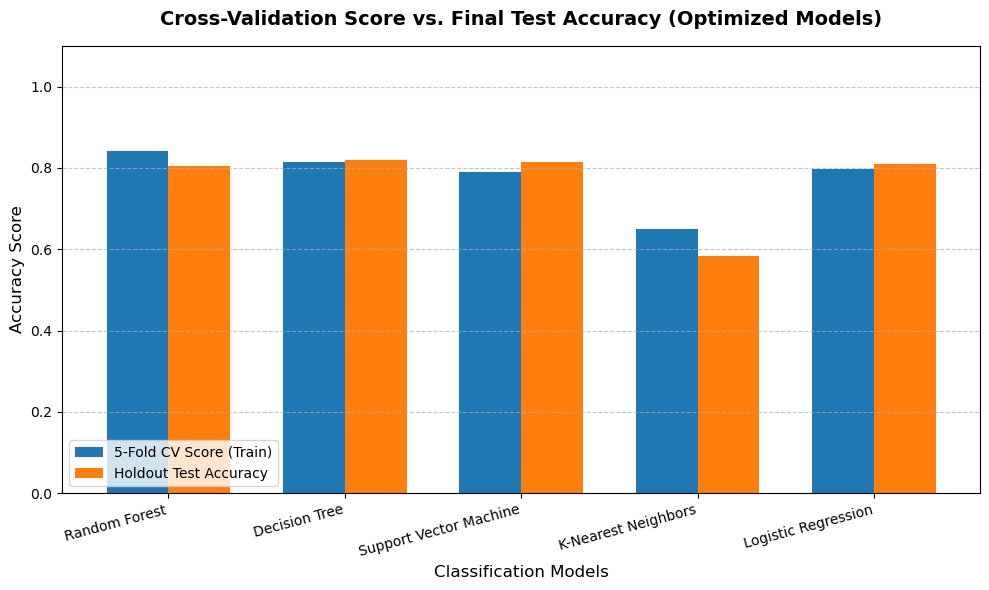

In [ ]:
# # 4. Visualize the comparison between Cross-Validation performance and Test performance
# df_plot = df_results.set_index('Model')[['Best CV Score', 'Test Accuracy']]
# ax = df_plot.plot(kind='bar', figsize=(10, 6), width=0.7)

# plt.title('Cross-Validation Score vs. Final Test Accuracy (Optimized Models)', fontsize=14, fontweight='bold', pad=15)
# plt.ylabel('Accuracy Score', fontsize=12)
# plt.xlabel('Classification Models', fontsize=12)
# plt.xticks(rotation=15, ha='right')
# plt.ylim(0, 1.1)
# plt.grid(axis='y', linestyle='--', alpha=0.7)
# plt.legend(['5-Fold CV Score (Train)', 'Holdout Test Accuracy'], loc='lower left')
# plt.tight_layout()
# plt.show()
